# Lab 03: The Post-API Age

*INFO 4617/5617 · Week 3 · Chapter 3, [The Post-API Age](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-03-post-api.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it. A **⏱ Microsprint** is a few minutes' task for you alone or with a neighbour, ending in something to share.

The chapter argues that access to web data is shrinking through enclosure, exemption, and erosion. Today we check that by measurement: what eight platforms say to a request with no credentials, who is really refusing when one says no, how three retired research endpoints fail, what the Wayback Machine remembers of them, and how differently six servers of one federated network answer the same question.

**The case:** the chapter's own audit ("Auditing Access Yourself"), its eight endpoints and three retired ones, run again today. Your table will differ from the chapter's and from your neighbour's; when and where you ran it is part of the result.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent. No keys and no accounts: every request today is anonymous on purpose.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell is filled in, and every cell ran against the live sites on 2026-10-21 at 21:56 UTC, from a cloud machine. An audit is a dated observation, so a rerun will differ in places. This run matched the chapter's 28 August table on all eight rows of Step 2, but the cloud machine's shared address draws rate limits that a laptop on campus probably won't: an earlier run that day got a 429 from Wikipedia in Step 2, and this run got one for the named request in Step 3's microsprint, where the earlier run got a 200. The Wayback Machine refused that earlier run with 429s; if it refuses in class, Step 5's cells stop with an error, which is the second question in Step 5's Discuss box. Counts (the Hacker News score, Mastodon's accounts) change by the minute. The lab follows the textbook at commit d9306b7.

## Step 0 — Set up (5 minutes)

Import `requests`, `pandas`, `matplotlib`, and `time`. Then define `HEADERS`, the User-Agent every request will send. Start from chapter 2's form, `WebDataScience/1.0 (your-email@colorado.edu)`, and add the one part Wikimedia's [User-Agent policy](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy) asks for at the end: the library and its version, `python-requests/` and `requests.__version__`. Step 3 tests whether the name matters.

Last, record when we ran the audit, in UTC, with [`pd.Timestamp.now()`](https://pandas.pydata.org/docs/reference/api/pandas.Timestamp.now.html). The chapter's outputs "were recorded on 28 August 2026, and yours will differ"; as its section on openness puts it, "an access matrix run once is a snapshot, while the same matrix run every semester is a record of enclosure happening."

In [1]:
# Import requests, pandas (as pd), matplotlib.pyplot (as plt), and time
# Define HEADERS: a dict whose "User-Agent" is "WebDataScience/1.0 (your-email@colorado.edu)",
#   a space, then "python-requests/" and requests.__version__
# Define AUDIT_DATE: the time now in UTC, as text like "2026-10-21 17:00 UTC"; print it and HEADERS
import requests
import pandas as pd
import matplotlib.pyplot as plt
import time

HEADERS = {"User-Agent": f"WebDataScience/1.0 (your-email@colorado.edu) python-requests/{requests.__version__}"}
AUDIT_DATE = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M UTC")
print(HEADERS)
print(f"Audit run {AUDIT_DATE}")

{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu) python-requests/2.34.2'}
Audit run 2026-10-21 21:56 UTC


<details>
<summary>💬 Discuss</summary>

- In week 2 we put our email address in a User-Agent. Who reads it on the other end today, and what could they do with it?
- Why is a measurement of access without its date worse than no measurement at all?
- Week 1 saved pageviews to a CSV because the data may change. What would we save from today's audit so that next semester's class could compare?

</details>

## Step 1 — One request, read the whole answer (10 minutes)

Before probing eight hosts, look closely at two. Ask Reddit's public JSON endpoint and Hacker News's API for their front pages, and for each print three parts of the [`Response`](https://requests.readthedocs.io/en/latest/api/#requests.Response) that week 1 introduced: the status code, the `content-type` header, and the start of the body. The chapter's point (in "An Access Matrix") is that what a host sends back is as informative as the code it sends: the content type tells you whether you received data at all.

In [2]:
# Reddit: https://www.reddit.com/r/python/hot.json?limit=1
# Hacker News: https://hacker-news.firebaseio.com/v0/topstories.json
# Request each with HEADERS; print its name, status code, and content-type header,
#   and under them the first 80 characters of the body, with !r. Sleep a second after each
FRONT_PAGES = {"Reddit": "https://www.reddit.com/r/python/hot.json?limit=1",
               "Hacker News": "https://hacker-news.firebaseio.com/v0/topstories.json"}
for name, url in FRONT_PAGES.items():
    response = requests.get(url, headers=HEADERS)
    print(f"{name}: {response.status_code} {response.headers['content-type']}")
    print(f"    {response.text[:80]!r}")
    time.sleep(1)

Reddit: 403 text/html
    '<body class=theme-beta><div><style>.theme-light,:root{--rem360:22.5rem;--rem320:'


Hacker News: 200 application/json; charset=utf-8
    '[50182987,50185869,50187708,50161346,50181114,50159726,50177916,50186037,5018113'


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** check what "open" means on Hacker News. Its front page is a list of story ids. Read it with `.json()`, count the ids, and request the first story's record from `https://hacker-news.firebaseio.com/v0/item/<id>.json`. Print its `type`, its `score`, and the names of its fields, but not their values: one of them is a person's username.
**Share:** how many ids the front page holds, and which fields an anonymous client gets for one story.

In [3]:
# Microsprint: request the Hacker News URL again, read it with .json() as ids, and print how many there are
# Request f"https://hacker-news.firebaseio.com/v0/item/{ids[0]}.json" and read it with .json() as item
# Print the item's type and score, and its field names with list(item)
ids = requests.get(FRONT_PAGES["Hacker News"], headers=HEADERS).json()
print(f"{len(ids)} story ids")
time.sleep(1)
item = requests.get(f"https://hacker-news.firebaseio.com/v0/item/{ids[0]}.json", headers=HEADERS).json()
print(f"type {item['type']}, score {item['score']}")
print(list(item))

500 story ids


type story, score 536
['by', 'descendants', 'id', 'kids', 'score', 'text', 'time', 'title', 'type', 'url']


<details>
<summary>💬 Discuss</summary>

- Both hosts answered. Which one answered the question we asked, and which header told you before you read the body?
- What would `response.json()` do with Reddit's answer, and what would the error message make you think was wrong?
- In week 2, Reddit's `robots.txt` was eight lines that disallow every path. Is today's 403 the same decision, enforced in a different place?

</details>

## Step 2 — The access matrix (14 minutes)

The chapter's first audit asks eight services one question: *if I show up with no credentials, what happens?* `TARGETS`, below, holds its eight endpoints, which ask for no key, no account, and no application. Write the chapter's `VERDICTS`, what a status code means for an anonymous request. Then ask each target once, and keep one row per answer, as a dict: the status, its verdict (looked up with [`dict.get`](https://docs.python.org/3/library/stdtypes.html#dict.get), so that an unlisted code is "other"), the content type, and the `x-ratelimit-limit` header, if the host sends one. A list of dicts becomes a [`DataFrame`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) in one line. The chapter gathers these lines into a function, `probe()`; we write them straight, in a loop that pauses a second after each host. Today the status code is the thing we measure, so a 403 is a row in the table, not an error. See "An Access Matrix".

In [4]:
# Given: the chapter's eight endpoints, from institutions built to share data to platforms built to fence it
TARGETS = {
    "Wikipedia":   "https://en.wikipedia.org/w/api.php?action=query&meta=siteinfo&format=json",
    "Hacker News": "https://hacker-news.firebaseio.com/v0/topstories.json",
    "arXiv":       "http://export.arxiv.org/api/query?search_query=all:electron&max_results=1",
    "Mastodon":    "https://mastodon.social/api/v1/instance",
    "Bluesky":     "https://public.api.bsky.app/xrpc/app.bsky.actor.getProfile?actor=bsky.app",
    "Reddit":      "https://www.reddit.com/r/python/hot.json?limit=1",
    "X (Twitter)": "https://api.twitter.com/2/tweets/search/recent?query=test",
    "Meta Graph":  "https://graph.facebook.com/v20.0/me",
}

In [5]:
# Define VERDICTS: 200 is "open", 401 and 403 are "gated", 429 is "rate-limited"
# For each target: request it with HEADERS, and append to rows a dict of api, status, verdict (VERDICTS.get,
#   else "other"), content_type (before any ";"), and rate_limit (the x-ratelimit-limit header). Sleep a second
# Make rows a DataFrame called access, and print it without the index
VERDICTS = {200: "open", 401: "gated", 403: "gated", 429: "rate-limited"}
rows = []
for name, url in TARGETS.items():
    response = requests.get(url, headers=HEADERS)
    rows.append({"api": name, "status": response.status_code,
                 "verdict": VERDICTS.get(response.status_code, "other"),
                 "content_type": response.headers.get("content-type", "").split(";")[0],
                 "rate_limit": response.headers.get("x-ratelimit-limit")})
    time.sleep(1)
access = pd.DataFrame(rows)
print(access.to_string(index=False))

        api  status verdict             content_type rate_limit
  Wikipedia     200    open         application/json        NaN
Hacker News     200    open         application/json        NaN
      arXiv     200    open     application/atom+xml        NaN
   Mastodon     200    open         application/json        300
    Bluesky     200    open         application/json        NaN
     Reddit     403   gated                text/html        NaN
X (Twitter)     401   gated application/problem+json        NaN
 Meta Graph     400   other         application/json        NaN


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** put the statuses the chapter recorded on 28 August 2026 in a dictionary, and print the rows of `access` whose status differs from the chapter's.
**Share:** which rows changed, if any, and for each, whether you think the platform changed or something on our side did.

In [6]:
# Microsprint: CHAPTER, the chapter's statuses: 200 for Wikipedia, Hacker News, arXiv, Mastodon, and Bluesky;
#   403 for Reddit, 401 for X (Twitter), 400 for Meta Graph
# Add a chapter_status column with .map(CHAPTER); print how many rows differ from it, and those rows
CHAPTER = {"Wikipedia": 200, "Hacker News": 200, "arXiv": 200, "Mastodon": 200, "Bluesky": 200,
           "Reddit": 403, "X (Twitter)": 401, "Meta Graph": 400}
access["chapter_status"] = access["api"].map(CHAPTER)
changed = access[access["status"] != access["chapter_status"]]
print(f"{len(changed)} of {len(access)} rows differ from the chapter's table")
print(changed[["api", "chapter_status", "status", "verdict", "content_type"]].to_string(index=False))

0 of 8 rows differ from the chapter's table
Empty DataFrame
Columns: [api, chapter_status, status, verdict, content_type]
Index: []


<details>
<summary>💬 Discuss</summary>

- Read the rows, not the totals. What do the open services have in common in who runs them, and what do the gated ones have in common?
- Mastodon's is the only row with a `rate_limit`. What does a budget stated up front let a careful client do that a 429 doesn't?
- Week 2's `responsible_get()` called `raise_for_status()`, which turns a 403 into an exception. What would that have done to Reddit's row, and to the cells after it?

</details>

## Step 3 — Read the failure, not just the status code (12 minutes)

Before writing down "Reddit blocks unauthenticated access," rule out a more boring explanation: that something between us and Reddit blocked it. The chapter's `diagnose()` prints who actually answered, and we write its lines straight, for Reddit's row: the `server` header (the software that sent the response), the [`via`](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Via) header (the proxies and caches it passed through on the way), the content type, and the start of the body, because a refusal usually says who is refusing. Read the headers with `.get()`, which gives `None` for a header the host didn't send. See "Reading the Failure, Not Just the Status Code".

In [7]:
# Request Reddit's endpoint, TARGETS["Reddit"], with HEADERS
# Print the status code, the server and via headers (with .get), the content-type,
#   and the first 120 characters of the body (with !r)
response = requests.get(TARGETS["Reddit"], headers=HEADERS)
print(f"status       {response.status_code}")
print(f"server       {response.headers.get('server')}")
print(f"via          {response.headers.get('via')}")
print(f"content-type {response.headers.get('content-type')}")
print(f"body         {response.text[:120]!r}")

status       403
server       snooserv
via          1.1 varnish
content-type text/html
body         '<body class=theme-beta><div><style>.theme-light,:root{--rem360:22.5rem;--rem320:20rem;--rem192:12rem;--rem144:9rem;--rem'


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** test the chapter's comment on its `HEADERS`, that "several of these hosts answer anonymous library defaults differently than they answer a named client." Send Wikipedia, Reddit, Hacker News, and Mastodon one request with no `headers` (so `requests` sends its default User-Agent) and one with `HEADERS`, and print the two statuses side by side.
**Share:** which hosts answer the two identities differently, and what the body says when one refuses.

In [8]:
# Microsprint: print requests' default User-Agent, requests.utils.default_user_agent()
# For Wikipedia, Reddit, Hacker News, and Mastodon: request TARGETS[name] once with no headers and once
#   with HEADERS, sleeping a second after each; print both status codes and the first
#   60 characters of the default request's body
print(f"default User-Agent: {requests.utils.default_user_agent()}")
for name in ["Wikipedia", "Reddit", "Hacker News", "Mastodon"]:
    default = requests.get(TARGETS[name])
    time.sleep(1)
    named = requests.get(TARGETS[name], headers=HEADERS)
    time.sleep(1)
    print(f"{name:<12} default {default.status_code}   named {named.status_code}   {default.text[:60]!r}")

default User-Agent: python-requests/2.34.2


Wikipedia    default 403   named 429   'Please set a user-agent and respect our robot policy https:/'


Reddit       default 403   named 403   '<body class=theme-beta><div><style>.theme-light,:root{--rem3'


Hacker News  default 200   named 200   '[50182987,50185869,50187708,50161346,50181114,50159726,50177'


Mastodon     default 200   named 200   '{"uri":"mastodon.social","title":"Mastodon.social","short_de'


<details>
<summary>💬 Discuss</summary>

- `snooserv` is Reddit's own server software. What would you have concluded if the `server` header had named a proxy you didn't choose, or the body had described your own network?
- The chapter's four-outcomes table says neither side can see the other's intent. What does a named User-Agent tell a platform about which row we're in, and what can't it tell?
- Week 2 said that after *hiQ* and *Van Buren*, legal risk concentrates at authentication gates and contracts, not at public visibility. Which of today's refusals is a gate in that sense, and which is a block page?

</details>

## Step 4 — Dead-endpoint forensics (15 minutes)

The chapter's second audit asks three retired research endpoints for data, and classifies *how* each refuses, because the manner of refusal says whether anything can still be recovered. Its categories are in `CAUSES`, below: 401 or 403 means the service is still running, for someone else; 404 means the host is alive but the endpoint was removed; and 400 means it still parses your request and rejects it without a token. The fourth category has no status code. A host that no longer answers sends no HTTP response at all, so `requests` has nothing to return and raises an error instead. That error is this step's finding, so this is the one cell today that catches one: put the request in a [`try`](https://docs.python.org/3/tutorial/errors.html#handling-exceptions) block, and under `except requests.ConnectionError` print the error's type as the evidence. See "Dead-Endpoint Forensics".

In [9]:
# Given: three retired endpoints that research once depended on, and the chapter's categories of refusal
RETIRED = {
    "Pushshift (Reddit archive)": "https://api.pushshift.io/reddit/search/submission/?q=test&size=1",
    "CrowdTangle (Meta)":         "https://api.crowdtangle.com/posts",
    "Twitter API v1.1":           "https://api.twitter.com/1.1/statuses/user_timeline.json?screen_name=nasa",
}
CAUSES = {
    200: "still open",
    400: "rejects the request without a token",
    401: "still running, credentials now required",
    403: "still running, credentials now required",
    404: "host alive, endpoint removed",
}

In [10]:
# For each retired endpoint, try: request it with HEADERS; print its name, status code, and cause
#   (CAUSES.get, else "other"), and under them the first 60 characters of the body (with !r)
# except requests.ConnectionError as error: print its name, None, "host does not answer", and type(error).__name__
# Sleep a second after each
for name, url in RETIRED.items():
    try:
        response = requests.get(url, headers=HEADERS)
        print(f"{name:<28} {response.status_code:<6} {CAUSES.get(response.status_code, 'other')}")
        print(f"    evidence: {response.text[:60]!r}")
    except requests.ConnectionError as error:
        print(f"{name:<28} {'None':<6} host does not answer")
        print(f"    evidence: {type(error).__name__}")
    time.sleep(1)

Pushshift (Reddit archive)   403    still running, credentials now required
    evidence: '{"detail":"Not authenticated"}'


CrowdTangle (Meta)           None   host does not answer
    evidence: ProxyError


Twitter API v1.1             400    rejects the request without a token
    evidence: '{"errors":[{"code":215,"message":"Bad Authentication data."}'


### ⏱ Microsprint (6 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 2. Make a DataFrame of at least five dated events from the chapter, across at least three platforms, each labelled with the pressure that fits it best (enclosure, exemption, or erosion), and plot them as a timeline: one row per event, in date order, coloured by pressure.
**Share:** your plot, and the event you found hardest to label.

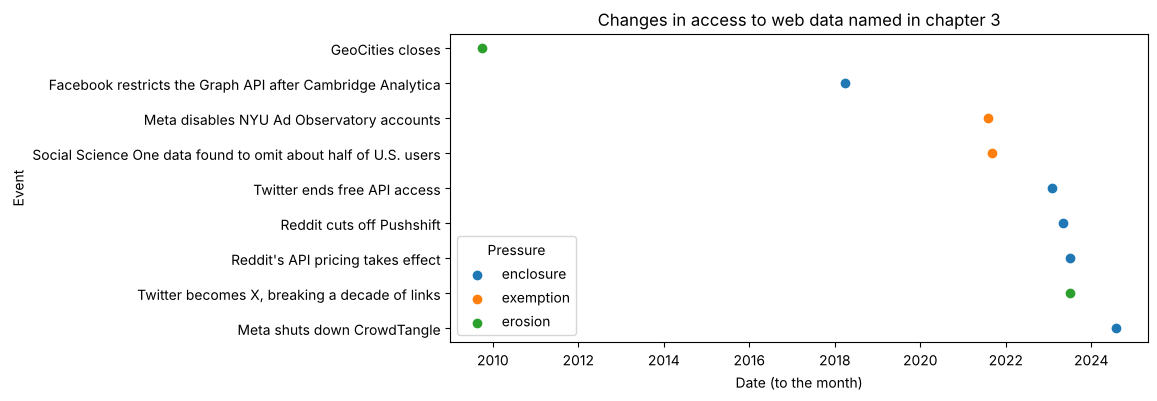

In [11]:
# Microsprint: EVENTS, a list of (date, event, pressure): five or more events from the chapter, from three or more platforms
# Make a DataFrame sorted by date; for each pressure, scatter its events (x the date, y the row) with a label
# Use the events as y tick labels, earliest at the top; add a legend, a title, and axis labels
# Dates to the month; the chapter gives some, and the rest are from news coverage of each event.
EVENTS = [
    ("2009-10", "GeoCities closes", "erosion"),
    ("2018-04", "Facebook restricts the Graph API after Cambridge Analytica", "enclosure"),
    ("2021-08", "Meta disables NYU Ad Observatory accounts", "exemption"),
    ("2021-09", "Social Science One data found to omit about half of U.S. users", "exemption"),
    ("2023-02", "Twitter ends free API access", "enclosure"),
    ("2023-05", "Reddit cuts off Pushshift", "enclosure"),
    ("2023-07", "Reddit's API pricing takes effect", "enclosure"),
    ("2023-07", "Twitter becomes X, breaking a decade of links", "erosion"),
    ("2024-08", "Meta shuts down CrowdTangle", "enclosure"),
]
events = pd.DataFrame(EVENTS, columns=["date", "event", "pressure"])
events["date"] = pd.to_datetime(events["date"])
events = events.sort_values("date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 4))
for pressure in ["enclosure", "exemption", "erosion"]:
    these = events[events["pressure"] == pressure]
    ax.scatter(these["date"], these.index, label=pressure)
ax.set_yticks(events.index, events["event"])
ax.invert_yaxis()
ax.legend(title="Pressure", loc="lower left")
ax.set_title("Changes in access to web data named in chapter 3")
ax.set_xlabel("Date (to the month)")
ax.set_ylabel("Event")
plt.show()

<details>
<summary>💬 Discuss</summary>

- Our requests send no `timeout=`. If a dead host dropped our packets instead of refusing them, what would Step 4's cell do, and how do the chapter's `autopsy()` and its "Common Issues to Debug" guard against that?
- On the timeline, when do the enclosure events bunch up? Does that fit the chapter's explanation of why enclosure accelerated when it did?
- Week 2 told the Cambridge Analytica story as one researcher's misuse of the Graph API. On the timeline it's an enclosure event for everyone. Who paid for it?

</details>

## Step 5 — What the archive remembers (10 minutes)

For an endpoint that's gone, the only evidence left is archival. The Wayback Machine's [availability API](https://archive.org/help/wayback_api.php) takes a `url` and answers, in JSON, with the closest capture it holds, under `["archived_snapshots"]["closest"]`. Ask it about Pushshift's and CrowdTangle's addresses, and print each capture's `timestamp`, pausing a second between the two requests. The chapter's `last_snapshot()` does the same, and also turns a 429 into a message: the archive is under constant load, and refuses an address that has asked too often (a classroom on one campus network is one address). We write the plain version, and talk about the 429 below. See "Dead-Endpoint Forensics".

In [12]:
# For api.pushshift.io and www.crowdtangle.com: request https://archive.org/wayback/available
#   with params={"url": page} and HEADERS; read its JSON, and print the page and the "timestamp"
#   of ["archived_snapshots"]["closest"]. Sleep a second after each
for page in ["api.pushshift.io", "www.crowdtangle.com"]:
    response = requests.get("https://archive.org/wayback/available", params={"url": page}, headers=HEADERS)
    closest = response.json()["archived_snapshots"]["closest"]
    print(f"{page:<24} {closest['timestamp']}")
    time.sleep(1)

api.pushshift.io         20230525131046


www.crowdtangle.com      20240814023608


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** the availability API also takes a `timestamp` (`YYYYMMDD`) and returns the capture closest to it. The chapter says the archive kept visiting www.crowdtangle.com until December 2024, but that every capture after 14 August 2024 "records only a redirect". Ask for the capture closest to 1 January 2024, 1 August 2024, 1 December 2024, and 1 June 2025, and print each capture's timestamp and `status`.
**Share:** the four captures you got back, and whether the archive ever handed you one from after 14 August 2024.

In [13]:
# Microsprint: for each date in 20240101, 20240801, 20241201, 20250601, ask the availability API for
#   www.crowdtangle.com with params {"url": ..., "timestamp": date}; sleep a second after each
# Print the date asked for, and the closest capture's timestamp and status
for date in ["20240101", "20240801", "20241201", "20250601"]:
    params = {"url": "www.crowdtangle.com", "timestamp": date}
    response = requests.get("https://archive.org/wayback/available", params=params, headers=HEADERS)
    closest = response.json()["archived_snapshots"]["closest"]
    print(f"{date} -> {closest['timestamp']} (status {closest['status']})")
    time.sleep(1)

20240101 -> 20240102062617 (status 200)


20240801 -> 20240802151503 (status 200)


20241201 -> 20240814023608 (status 200)


20250601 -> 20240814023608 (status 200)


<details>
<summary>💬 Discuss</summary>

- The chapter reads these timestamps as the shutdowns themselves, written in the archival record. What else could make a site's last capture fall on a given day?
- Our cells assume the archive answers with JSON. What happens to them if it sends a 429, as the chapter warns a shared address will, and what does the chapter's "Common Issues to Debug" tell you to do then?
- The chapter calls the Wayback Machine counter-erosion infrastructure. Which of the three counter-values does it embody, and what happens to that value if the archive itself closes?

</details>

## Step 6 — No single Mastodon (14 minutes)

Federated platforms, the chapter says, solve some access problems "while complicating basic measurement: there is no single API endpoint for 'all of Mastodon,' because there is no single Mastodon." Let's measure that. The six servers below run the same software and speak the same protocol, but each server's administrators set its terms. Ask each for its description, [`/api/v1/instance`](https://docs.joinmastodon.org/methods/instance/#v1), which reports how many accounts it has. Then ask each, with no credentials, for one post from its [public timeline](https://docs.joinmastodon.org/methods/timelines/#public), and keep only the status code: the post belongs to someone. Sort the table so that the servers that answered alike sit together, and plot their sizes, coloured by whether an anonymous client may read their public timeline. See "Erosion" and "Ownership".

In [14]:
# INSTANCES: mastodon.social, mastodon.online, fosstodon.org, hachyderm.io, sigmoid.social, scholar.social
# For each domain: get https://{domain}/api/v1/instance and sleep a second; get its public timeline,
#   https://{domain}/api/v1/timelines/public, with params={"limit": 1}, and sleep again. Append to rows a dict of
#   server, accounts (the instance's ["stats"]["user_count"]), and public_timeline (the timeline's status code)
# Make rows a DataFrame called servers, sorted by public_timeline and then accounts; print it
INSTANCES = ["mastodon.social", "mastodon.online", "fosstodon.org",
             "hachyderm.io", "sigmoid.social", "scholar.social"]
rows = []
for domain in INSTANCES:
    info = requests.get(f"https://{domain}/api/v1/instance", headers=HEADERS)
    time.sleep(1)
    public = requests.get(f"https://{domain}/api/v1/timelines/public", params={"limit": 1}, headers=HEADERS)
    time.sleep(1)
    rows.append({"server": domain, "accounts": info.json()["stats"]["user_count"], "public_timeline": public.status_code})
servers = pd.DataFrame(rows).sort_values(["public_timeline", "accounts"])
print(servers.to_string(index=False))

         server  accounts  public_timeline
 sigmoid.social     12243              200
   hachyderm.io     57928              200
  fosstodon.org     62711              200
 scholar.social      1227              422
mastodon.online    188255              422
mastodon.social   3443379              422


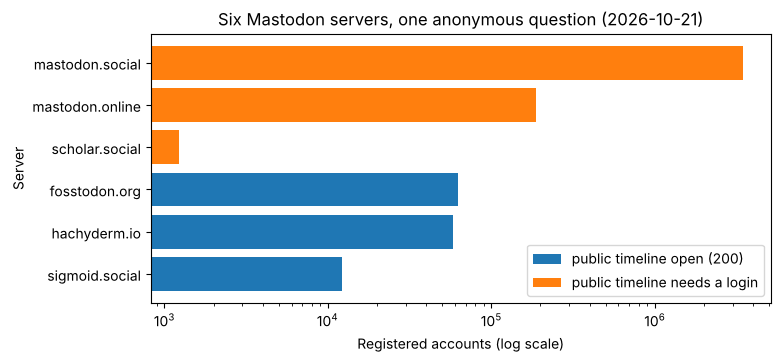

In [15]:
# Split servers into opened (public_timeline 200) and closed (the rest); plot each with ax.barh,
#   server against accounts, with a label; use a log x scale, a title, axis labels, and a legend
opened = servers[servers["public_timeline"] == 200]
closed = servers[servers["public_timeline"] != 200]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(opened["server"], opened["accounts"], label="public timeline open (200)")
ax.barh(closed["server"], closed["accounts"], label="public timeline needs a login")
ax.set_xscale("log")
ax.legend(loc="lower right")
ax.set_title(f"Six Mastodon servers, one anonymous question ({AUDIT_DATE[:10]})")
ax.set_xlabel("Registered accounts (log scale)")
ax.set_ylabel("Server")
plt.show()

### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 4. Pick a project that depends on one of today's open rows (Wikipedia, Hacker News, arXiv, Mastodon, or Bluesky). Suppose it closes halfway through your study. From the chapter's "Build" list (research access programs, data donation, independent archives, public records requests, crowdsourcing, shared research infrastructure), choose three backups, and for each write what it trades away: comprehensiveness, reliability, or resolution.
**Share:** your source, your first backup, and what it costs you.

In [16]:
# Microsprint: your project and its source; three backups from the chapter's "Build" list, each with what it trades away
# Project: how six Mastodon servers' moderation rules changed over a semester (source: each server's public API)
# 1. Independent archive: the Wayback Machine's captures of each server's /about page. Trades away
#    resolution: captures come when the crawler visits, not every week, and a page may have none.
# 2. Data donation: ask each server's administrators for their rule history. Trades away
#    comprehensiveness: only the servers that agree are in the study.
# 3. Shared research infrastructure: start our own weekly collection now and deposit it (week 1's CSV, dated).
#    Trades away reliability only if we stop; it can't recover the weeks before we started.

<details>
<summary>💬 Discuss</summary>

- Same software, same protocol, different answers. Whose decision is "this server's public timeline needs a login", and is it enclosure in the chapter's sense?
- If a paper says "we sampled posts from Mastodon", what must its methods section say for a reader to know what was observed and what couldn't be?
- The chapter pairs ownership against erosion. Which of your microsprint's backups is held by a community, and which could one organization retire?

</details>

## Step 7 — What did we learn? (5 minutes)

In a few sentences, as comments or in a Markdown cell:

- How many of the eight endpoints were open when we ran the audit, and which rows differed from the chapter's 28 August table? Was each difference the platform, or us?
- Which refusals came from the platform itself, and what in Step 3's headers or the identity microsprint showed it?
- Of the three retired endpoints, which is gone, which is gated, and which is repriced? Which leaves someone to negotiate with?
- How many of the six Mastodon servers let an anonymous client read their public timeline? What does that do to the sentence "we collected data from Mastodon"?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, identify yourself: Step 0's `HEADERS`.
- Step 2, probe the OpenAlex anchor by hand: Step 1's single request, read whole, and Step 2's `rate_limit` column, which reads one `X-RateLimit` header.
- Step 3, build the institutional matrix: Step 2's loop, `VERDICTS`, and table, and Step 0's `AUDIT_DATE`. The chapter's `probe()` is the same lines as a function, and adds the `Int64` status column for a host that never answers, like CrowdTangle in Step 4.
- Step 4, extend it with two institutions of your own: Step 2's `TARGETS` and its loop.
- Step 5, attribute a refusal: Step 3's lines (the chapter's `diagnose()`), and its microsprint's second identity.
- Step 6, autopsy a retired institutional endpoint: Step 4's loop and `CAUSES` (the chapter's `autopsy()`).
- Step 7, interpret: Step 1 (a refusal can arrive with the wrong content type), Step 4's categories, and Step 6's microsprint on where data goes when a source closes.

In [17]:
# Your answers here, as comments
# 1. All eight endpoints answered as in the chapter's 28 August table, so 0 of 8 rows differed: five open
#    (Wikipedia, Hacker News, arXiv, Mastodon, Bluesky), Reddit 403, X 401, Meta Graph 400. An earlier run
#    the same day got a 429 from Wikipedia; that was us (a cloud machine's shared address), not Wikipedia.
# 2. Reddit's 403 came from Reddit: the server header was snooserv, Reddit's own software, behind a varnish
#    cache, and the body was Reddit's page, not our network's. Wikipedia refused requests' default
#    User-Agent with a 403 and its own message ("Please set a user-agent and respect our robot policy").
# 3. CrowdTangle is gone: no HTTP answer at all (a ProxyError here). Pushshift is gated: a 403 with
#    {"detail":"Not authenticated"}. Twitter v1.1 is repriced: a 400 with error 215. Pushshift and Twitter
#    leave someone to negotiate with; CrowdTangle leaves only the archive, whose last capture of
#    www.crowdtangle.com it would hand us was from 14 August 2024, even when we asked for 2025.
# 4. Three of six: sigmoid.social, hachyderm.io, and fosstodon.org answered 200; mastodon.social,
#    mastodon.online, and scholar.social answered 422 and want a login. Size doesn't predict it: the largest
#    (3.4 million accounts) and the smallest (about 1,200) are both closed. "We collected data from Mastodon"
#    means nothing until it names the servers and what each let an anonymous client read.

## Friday: from the lab to the textbook (15 minutes)

The lab ran the chapter's audit again, so it's a good place to look for what has changed or what confused you. Some places to start:

- **Outputs that have changed.** The chapter's tables were recorded on 28 August 2026. Which of our rows differed (Step 2's microsprint), and does the chapter's text around them still hold?
- **Code that broke, or nearly did.** Our cells send no `timeout=` and catch no errors, except Step 4's one `try`. The chapter's `probe()` and `autopsy()` pass a timeout and catch a request that never completes, and its "Common Issues to Debug" says why. Did any of our cells stall or stop, and does the chapter warn readers clearly enough about what would?
- **A sentence to check.** Step 5's microsprint tested the chapter's claim about CrowdTangle's later captures. Did the availability API show you what the chapter describes?
- **A microsprint that could be an exercise.** Step 6 measured, in a few lines, a claim the chapter makes in one sentence. Would it make a good Additional Exercise?

See [`handouts/common/revision-framework.md`](../../handouts/common/revision-framework.md) for how to propose a revision, as an issue or a pull request.